170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2019s 12us/step
訓練資料 X_train 形狀: (50000, 32, 32, 3)
訓練標籤 y_train 形狀: (50000, 1)
測試資料 X_test 形狀: (10000, 32, 32, 3)
測試標籤 y_test 形狀: (10000, 1)


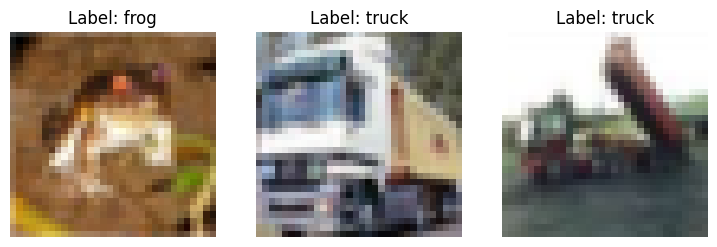

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 445ms/step - accuracy: 0.4521 - loss: 1.5152 - val_accuracy: 0.5683 - val_loss: 1.3270
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 137s 439ms/step - accuracy: 0.5841 - loss: 1.1691 - val_accuracy: 0.6189 - val_loss: 1.1495
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 435ms/step - accuracy: 0.6392 - loss: 1.0203 - val_accuracy: 0.6504 - val_loss: 1.0679
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 432ms/step - accuracy: 0.6812 - loss: 0.9054 - val_accuracy: 0.6708 - val_loss: 1.0227
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 136s 436ms/step - accuracy: 0.7175 - loss: 0.8072 - val_accuracy: 0.6653 - val_loss: 0.9745
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 443ms/step - accuracy: 0.7459 - loss: 0.7255 - val_accuracy: 0.6941 - val_loss: 0.8989
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 450ms/step - accuracy: 0.7730 - loss: 0.6457 - val_accuracy: 0.7154 - val_loss: 0.8595
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 430ms/step - accuracy: 0.8016 -

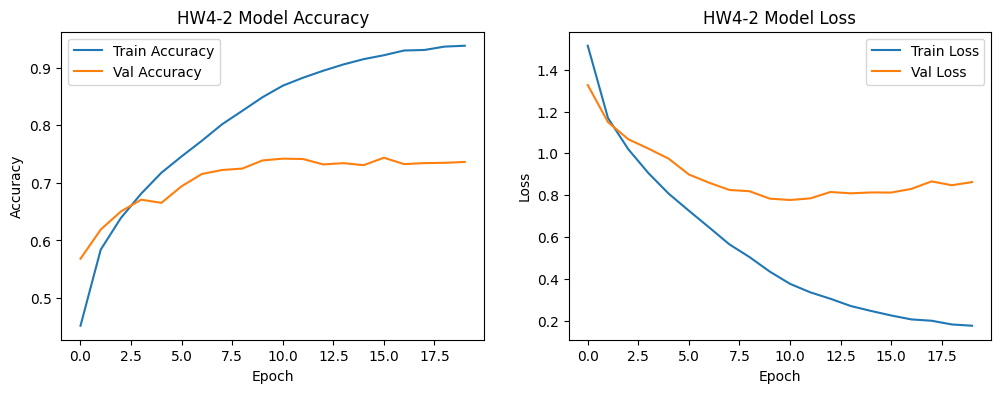

HW4-2 測試資料集準確率: 73.64%
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step


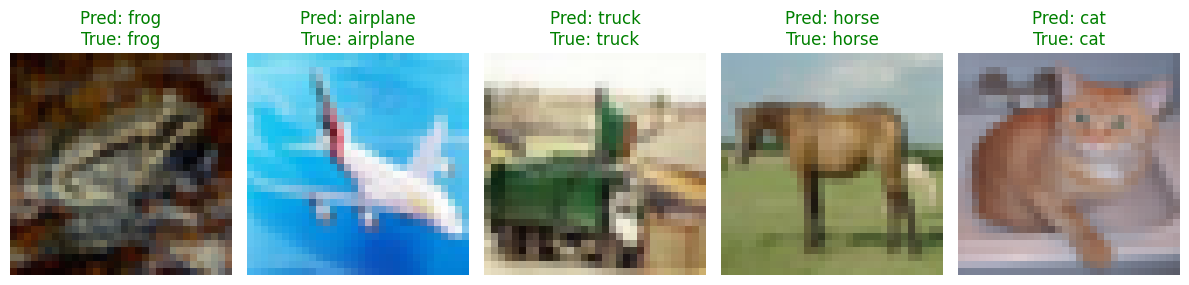

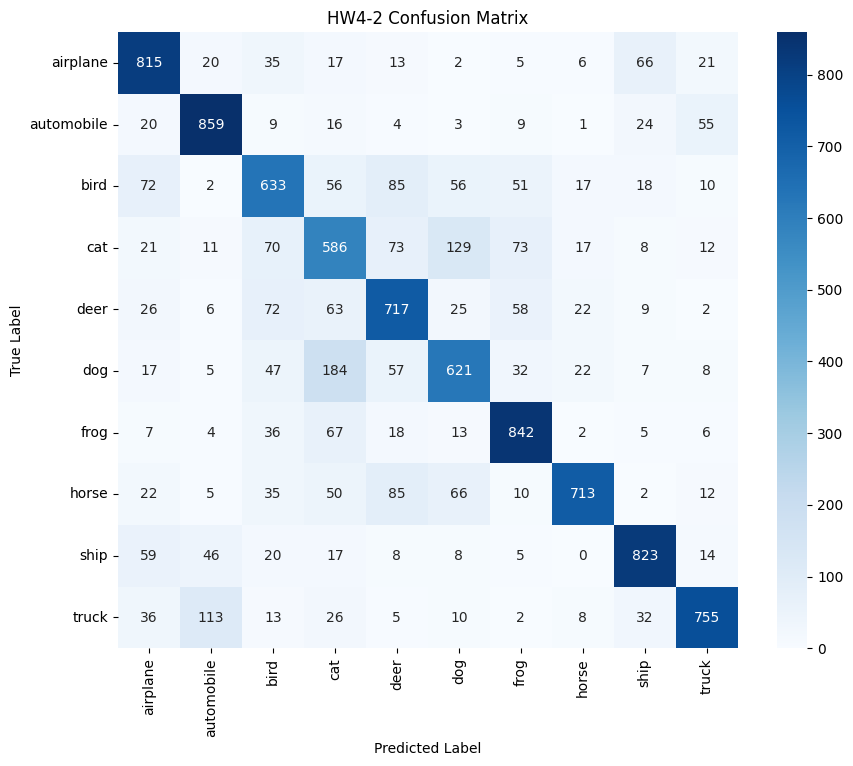

模型已成功儲存為 hw4_2_model.keras


interactive(children=(IntSlider(value=0, description='index', max=999), Button(description='Run Interact', sty…

<function __main__.predict_test_image(index)>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import seaborn as sns
import ipywidgets as widgets

# ==========================================
# 1. 資料預處理
# ==========================================
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("訓練資料 X_train 形狀:", X_train.shape)
print("訓練標籤 y_train 形狀:", y_train.shape)
print("測試資料 X_test 形狀:", X_test.shape)
print("測試標籤 y_test 形狀:", y_test.shape)

# 呈現三張訓練圖片及其真實標籤名稱
plt.figure(figsize=(9, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Label: {class_names[y_train[i][0]]}")
    plt.axis('off')
plt.show()

# 正規化與 One-hot Encoding
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

# ==========================================
# 2. 建立神經網路模型 (HW4-2 規格)
# ==========================================
model = Sequential([
    # 第 01 層：卷積層，32 個 Filter，尺寸 (5, 5)，ReLU
    Conv2D(32, (5, 5), padding='same', input_shape=(32, 32, 3), activation='relu'),
    # 第 02 層：Dropout 0.25
    Dropout(0.25),
    # 第 03 層：池化層，池化尺寸 (2, 2)
    MaxPooling2D(pool_size=(2, 2)),

    # 第 04 層：卷積層，64 個 Filter，尺寸 (3, 3)，ReLU
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    # 第 05 層：Dropout 0.25
    Dropout(0.25),
    # 第 06 層：池化層，池化尺寸 (2, 2)
    MaxPooling2D(pool_size=(2, 2)),

    # 第 07 層：拉平層
    Flatten(),
    # 第 08 層：Dropout 0.25
    Dropout(0.25),
    # 第 09 層：全連接層，1024 個神經元，ReLU
    Dense(1024, activation='relu'),
    # 第 10 層：Dropout 0.25
    Dropout(0.25),
    # 第 11 層：全連接層，10 個神經元，Softmax
    Dense(10, activation='softmax')
])

model.summary()

# ==========================================
# 3. 訓練神經網路模型
# ==========================================
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    X_train, y_train_onehot,
    batch_size=128,
    epochs=20,
    validation_split=0.2,
    verbose=1
)

# ==========================================
# 4. 顯示訓練過程的 Loss & Accuracy
# ==========================================
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('HW4-2 Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('HW4-2 Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# ==========================================
# 5. 評估模型準確率
# ==========================================
test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0)
print(f"HW4-2 測試資料集準確率: {test_acc * 100:.2f}%")

# ==========================================
# 6. 進行預測與展示
# ==========================================
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))
for i in range(5):
    idx = np.random.randint(0, len(X_test))
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx])
    pred_name = class_names[predicted_classes[idx]]
    true_name = class_names[y_test[idx][0]]
    color = 'green' if predicted_classes[idx] == y_test[idx][0] else 'red'
    plt.title(f"Pred: {pred_name}\nTrue: {true_name}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

# ==========================================
# 7. 混淆矩陣 (Confusion Matrix)
# ==========================================
cm = confusion_matrix(y_test, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('HW4-2 Confusion Matrix')
plt.show()

# ==========================================
# 8. 儲存完整模型 (.keras 格式)
# ==========================================
model.save("hw4_2_model.keras")
print("模型已成功儲存為 hw4_2_model.keras")

# ==========================================
# 9. interact_manual 互動預測
# ==========================================
def predict_test_image(index):
    img = X_test[index]
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

    pred_prob = model.predict(np.expand_dims(img, axis=0), verbose=0)
    pred_idx = np.argmax(pred_prob)
    print(f"真實標籤: {class_names[y_test[index][0]]}")
    print(f"預測結果: {class_names[pred_idx]} (信心機率: {pred_prob[0][pred_idx]*100:.2f}%)")

widgets.interact_manual(predict_test_image, index=widgets.IntSlider(min=0, max=999, step=1, value=0))